In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import pandas as pd 

# Übungsblatt 1 in Mechanistische Effektmodellierung 2026: GUTS

### Hinweis:
Entpacken Sie die auf Vips bereitgestellte zip-Datei in dem Ordner, in dem sich dieses Notebook befindet.

## Aufgabe 1: TK-Modell

Eins der einfachsten TK-Modelle, das auch für Full-GUTS verwendet wird, ist das Diffusionsmodell zwischen zwei Phasen:
$$
\frac{dC_i}{dt} = k_e \left( K_{iw}C_W  - C_i \right)
$$

$C_i$ beschreibt die interne Konzentration und $C_W$ die externe Koncentration. <br>

Der Verteilungskoeffizient zwischen Organismus und Wasser ($K_{iw}$) wird oft als Biokonzentrationsfaktor bezeichnet (siehe MKS/Angleichungsmodul).


Die Ratenkonstante $k_e$ beeinflusst sowohl Eliminierung als auch, zusammen mit $K_{iw}$, die Aufnahme der Substanz. <br>
Am besten betrachtet man $k_e$ als Ratenkonstante, die die Equilibrierungsgeschwindikeit zwischen Organismus und Medium bestimmt.

### A1a  
Implementieren Sie das beschriebene Modell in Python und simulieren Sie über 40 Zeiteinheiten. Plotten Sie den Verlauf von $C_i$ über der Zeit mit den folgenden Parameterwerten.

In [2]:
p = {
    'k_e' : 0.2,
    'K_iw' : 1,
    'C_W' : 1
}

Text(0.5, 1.0, 'C_i over time')

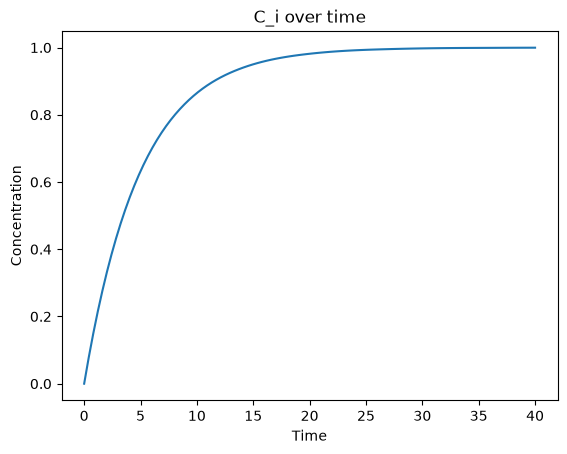

In [3]:
# Lösung
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def tk_model(t,y, p):
    C_i = y[0]
    dC_i_dt = p['k_e'] * (p['C_W']*p['K_iw'] - C_i)
    return [dC_i_dt]

C_i = solve_ivp(tk_model, [0, 40], [0], args=(p,), dense_output=True)

plt.figure()
t = np.linspace(0, 40, 100)
plt.plot(t, C_i.sol(t)[0], label='C_i(t)')
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('C_i over time')

Bisher haben wir $C_w$ als konstant angenommen. Wenn $C_w$ nicht konstant ist liegen meistens nur ein paar wenige Messungen der Konzentration im Wasser vor. Um zeitkontinuirlich zu simulieren wird jedoch für jeden möglichen Zeitpunkt ein Wert benötigt: Wir müssen $C_w$ interpolieren. 

### A1b
In der folgenden CSV-Datei sind 3 Expositionsszenarien gegeben, für die zu jeweils 3 Zeitpunkten die Konzentration im Wasser $C_w$ gegeben ist. Interpolieren Sie die gegebenen Werte linear, plotten Sie den resultierenden Verlauf von $C_w$ über der Zeit. Simulieren Sie im Anschluss das simple TK-Modell für alle 3 Szenarien über 50 Zeiteinheiten und plotten Sie alle 3 sich ergebenden Zeitverläufe von $C_i$ in einem einzelnen weiteren plot.

In [4]:
from scipy.interpolate import interp1d
import pandas as pd
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.interp1d.html

exposures = pd.read_csv("data/TK_exposure_scenarios_01.csv")
exposures

c:\Users\luede\Documents\Github\Uni_Projects\.venv\Lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


,scenario,t,C_W
0,1,0,0.10
1,1,30,0.10
2,1,50,0.00
3,2,0,0.25
4,2,30,0.25
5,2,50,0.00
6,3,0,0.50
7,3,30,0.50
8,3,50,0.00


<Figure size 640x480 with 0 Axes>

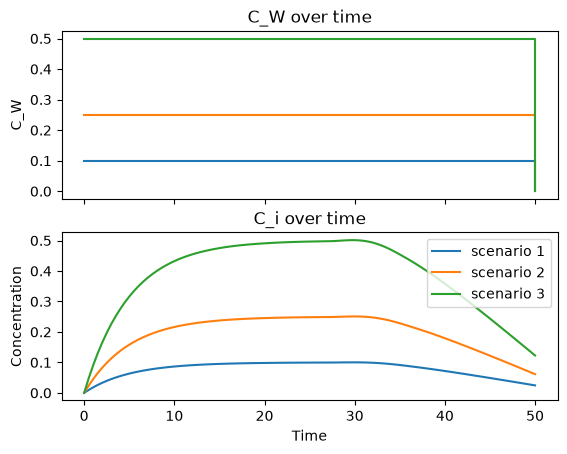

In [5]:
# Lösung
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy import interpolate
p = {
    'k_e' : 0.2,
    'K_iw' : 1
}

def tk_model(t,y, p,C_w):
    C_i = y[0]
    dC_i_dt = p['k_e'] * (C_w(t) * p['K_iw'] - C_i)
    return [dC_i_dt] 

plt.figure()
fig, ax = plt.subplots(2, 1, sharex=True)

for i in range(3):
    ex_sceni = exposures[exposures['scenario'] == i+1]
    C_w = interpolate.interp1d(ex_sceni['t'], ex_sceni['C_W'], fill_value="extrapolate")

    ax[0].step(ex_sceni["t"], ex_sceni["C_W"], where="post")

    C_i = solve_ivp(tk_model, [0, 50], [0], args=(p,C_w), dense_output=True)
    ax[1].plot(np.linspace(0, 50, 100), C_i.sol(np.linspace(0, 50, 100))[0], label='scenario {}'.format(i+1))

ax[0].set_ylabel('C_W')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('C_i')

plt.ylabel('Concentration')
ax[0].set_title('C_W over time')
ax[1].set_title('C_i over time')
plt.legend()
plt.show()


### A1c

Ändern Sie die Interpolationsmethode von linear zu stufenförmig und wiederholen Sie die Simulationen. Nehmen Sie Stellung zur Relevanz der Wahl der Interpolationsmethode für das Ergebnis. Worauf sollte in der Anwendung geachtet werden? Unter welchen Umständen würden sie welche der beiden Methoden verwenden? Begründen Sie.

<Figure size 640x480 with 0 Axes>

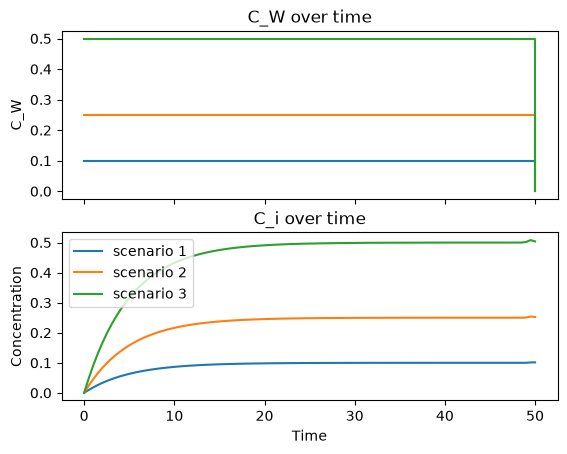

In [6]:

# Lösung
plt.figure()
fig, ax = plt.subplots(2, 1, sharex=True)
for i in range(3):
    ex_sceni = exposures[exposures['scenario'] == i+1]
    C_w = interpolate.interp1d(ex_sceni['t'], ex_sceni['C_W'],kind="previous",fill_value="extrapolate")
    
    ax[0].step(ex_sceni["t"], ex_sceni["C_W"], where="post")

    C_i = solve_ivp(tk_model, [0, 60], [0], args=(p,C_w), dense_output=True)
    
    ax[1].plot(np.linspace(0, 50, 100), C_i.sol(np.linspace(0, 50, 100))[0], label='scenario {}'.format(i+1))
    

ax[0].set_ylabel('C_W')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('C_i')

plt.ylabel('Concentration')
ax[0].set_title('C_W over time')
ax[1].set_title('C_i over time')
plt.legend()
plt.show()


Antwort:  
Die wahl der Interpolationsmethode verändert die Ergebnisse drastisch, weil wir damit den Zeitpunkten für die wir keine Messung haben einen Wert zuschreiben. Das verkörpert eine zusätzliche Annahme mit der wir das Modell füttern. Es ist in der Anwendung wichtig, zu prüfen welche Annahme plausibel für das untersuchte System ist.

linear wenn die externe konzentration tatsählich linear verwässert wird.

Stufenweise wenn der untersuchte Organismus in ein anderes Gewässer gesteckt wird. 

Es sind natürlich auch deutlich komplexere Expositionsprofile möglich. FOCUS-Expositionsprofile (FOrum for the Co-ordination of pesticide fate models and their USe) sind standardisierte Simulationsmodelle und Szenarien, die von der Europäischen Behörde für Lebensmittelsicherheit (EFSA) genutzt werden. 

### A1d
Die Datei `data/profile_focus.csv` enthält ein solches Expositionsprofil. Importieren Sie es und simulieren Sie das TK-Modell unter Annahme dieses Szenarios und linearer Interpolation. Plotten sie wie bisher $C_w$ und $C_i$ im Zeitverlauf.

In [7]:
focus_exposures = pd.read_csv("data/profile_focus.csv")
focus_exposures

,t,C_W
0,0.000,0.00000
1,0.042,0.00003
2,0.083,0.00006
3,0.125,0.00009
4,0.167,0.00012
...,...,...
11636,484.833,0.00002
11637,484.875,0.00002
11638,484.917,0.00002
11639,484.958,0.00002


<Figure size 640x480 with 0 Axes>

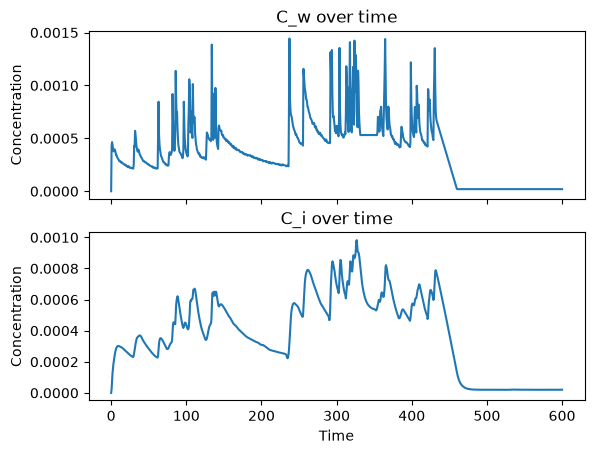

In [8]:
# Lösung

plt.figure()
fig, ax = plt.subplots(2, 1, sharex=True)

C_w = interpolate.interp1d(focus_exposures['t'], focus_exposures['C_W'], fill_value="extrapolate")
# plot C_w via C_w(t)
ax[0].plot(np.linspace(0, 600, 1000), C_w(np.linspace(0, 600, 1000)))
#plt.plot(ex_sceni['t'], ex_sceni['C_W'], label='C_w(t) scenario {}'.format(i+1))
C_i = solve_ivp(tk_model, [0, 600], [0], args=(p,C_w), dense_output=True)
ax[1].plot(np.linspace(0, 600, 1000), C_i.sol(np.linspace(0, 600, 1000))[0])

ax[1].set_xlabel('Time')
#plt.yscale('log')
#plt.xscale('log')
ax[0].set_ylabel('Concentration')
ax[1].set_ylabel('Concentration')
ax[0].set_title('C_w over time')
ax[1].set_title('C_i over time')

plt.show()

## Aufgabe 2: GUTS-Reduced
Bearbeiten Sie nun einen Datensatz, der am UFZ in Leipzig erstellt wurde mithilfe von GUTS-Modellen. In der Untersuchung ging es um die Hypothese, dass UV-B Strahlung die Wirkung des Pestizids Esfenvalerat verstärkt. Bevor wir uns mit der Wirkung der Interaktion des Pestizids beschäftigen, schauen wir uns die Exposition mit UV-B Strahlung genauer an. UV-B Strahlung verursacht DNA Schäden und ROS (reactive oxygen species), welche oxidativen Stress auf Zellmembranen, Proteine und DNA ausüben. Sie wird hier als Bestrahlungsstärke in der Einheit $mW*cm^{-2}$ angegeben.

<i>
Hinweis:  
  
Du kannst mempy mit dem folgenden command in dein conda environment installieren:  
</i>
<code>
pip install "mempyguts[pymob] @ git+https://gitlab.uni-osnabrueck.de/memuos/mempyguts.git@61-mempy-fit-not-compatible-with-some-models"
</code>

In [9]:
import mempy
from mempy.model import RED_SD

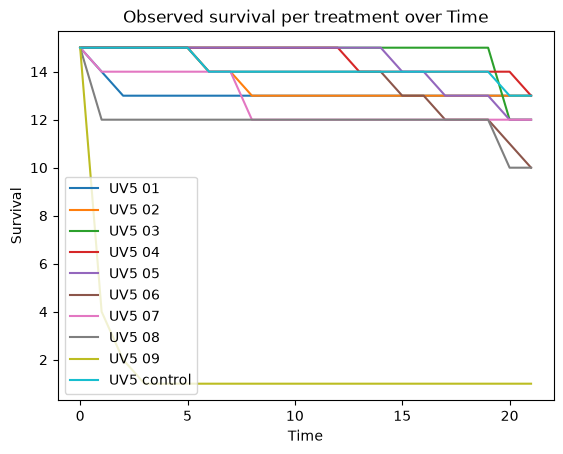

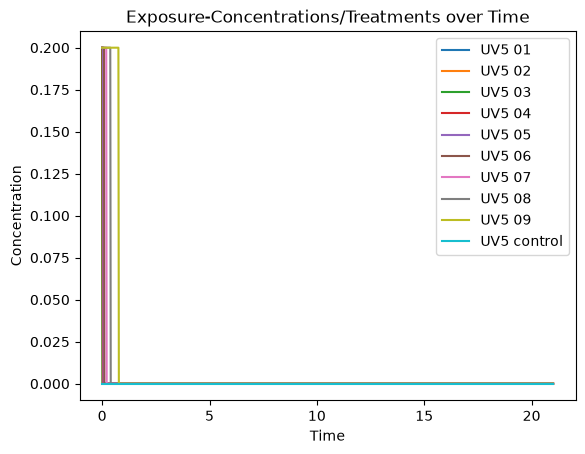

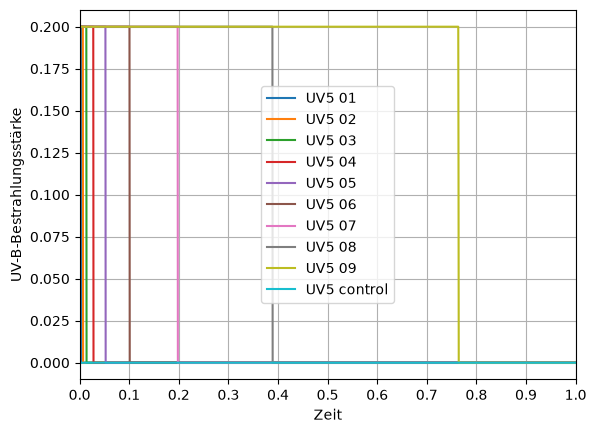

In [23]:
exposure_funcs, survival_data, num_expos = mempy.input_data.read_exposure_survival(
    "data/uvb_esfenvalerate/uv/", "openguts_survival.xlsx", 
    exposure_name="uv",
    survival_name="survival",
    info_name="meta",
    visualize=True
)

import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1, 2000)

for szenario, exposition in exposure_funcs["uv"].items():
    plt.plot(t, exposition(t), label=szenario)

plt.xlim(0, 1)
plt.xticks(np.arange(0, 1.1, 0.1))
plt.xlabel("Zeit")
plt.ylabel("UV-B-Bestrahlungsstärke")
plt.legend()
plt.grid()
plt.show()

### A2a
Wir betrachten hier keine Chemikalie sondern einen andersartigen Stressor: UV-B-Strahlung. Überlegen Sie ob diese Nutzung von GUTS-RED konzeptionell zulässig ist oder nicht und argumentieren Sie. Könnte man auch Full-GUTS für die Modellierung verwenden? Begründen Sie und notieren Sie ihre Gedanken.

Antwort:

Da wir keine interne Konzentration haben ergibt es sehr viel Sinn die GUTS-RED zu nutzen. Der abtrakte Damage kann berechnet werden ohne eine interne Konzentration festzustellen. Full GUTS macht dabei weniger Sinn, eben weil es keine interne Konzentration von UV Strahung gibt.

### A2b
Rufen Sie sich die Funktionsweise des GUTS-RED-SD-Modells in Erinnerung und die Bedeutung seiner Parameter. Versuchen Sie die mit dem GUTS-RED-SD-Modell simulierten Survival Kurven an die Daten anzupassen, indem sie die Parameter manuell verändern.

In [11]:
modelsd = RED_SD()

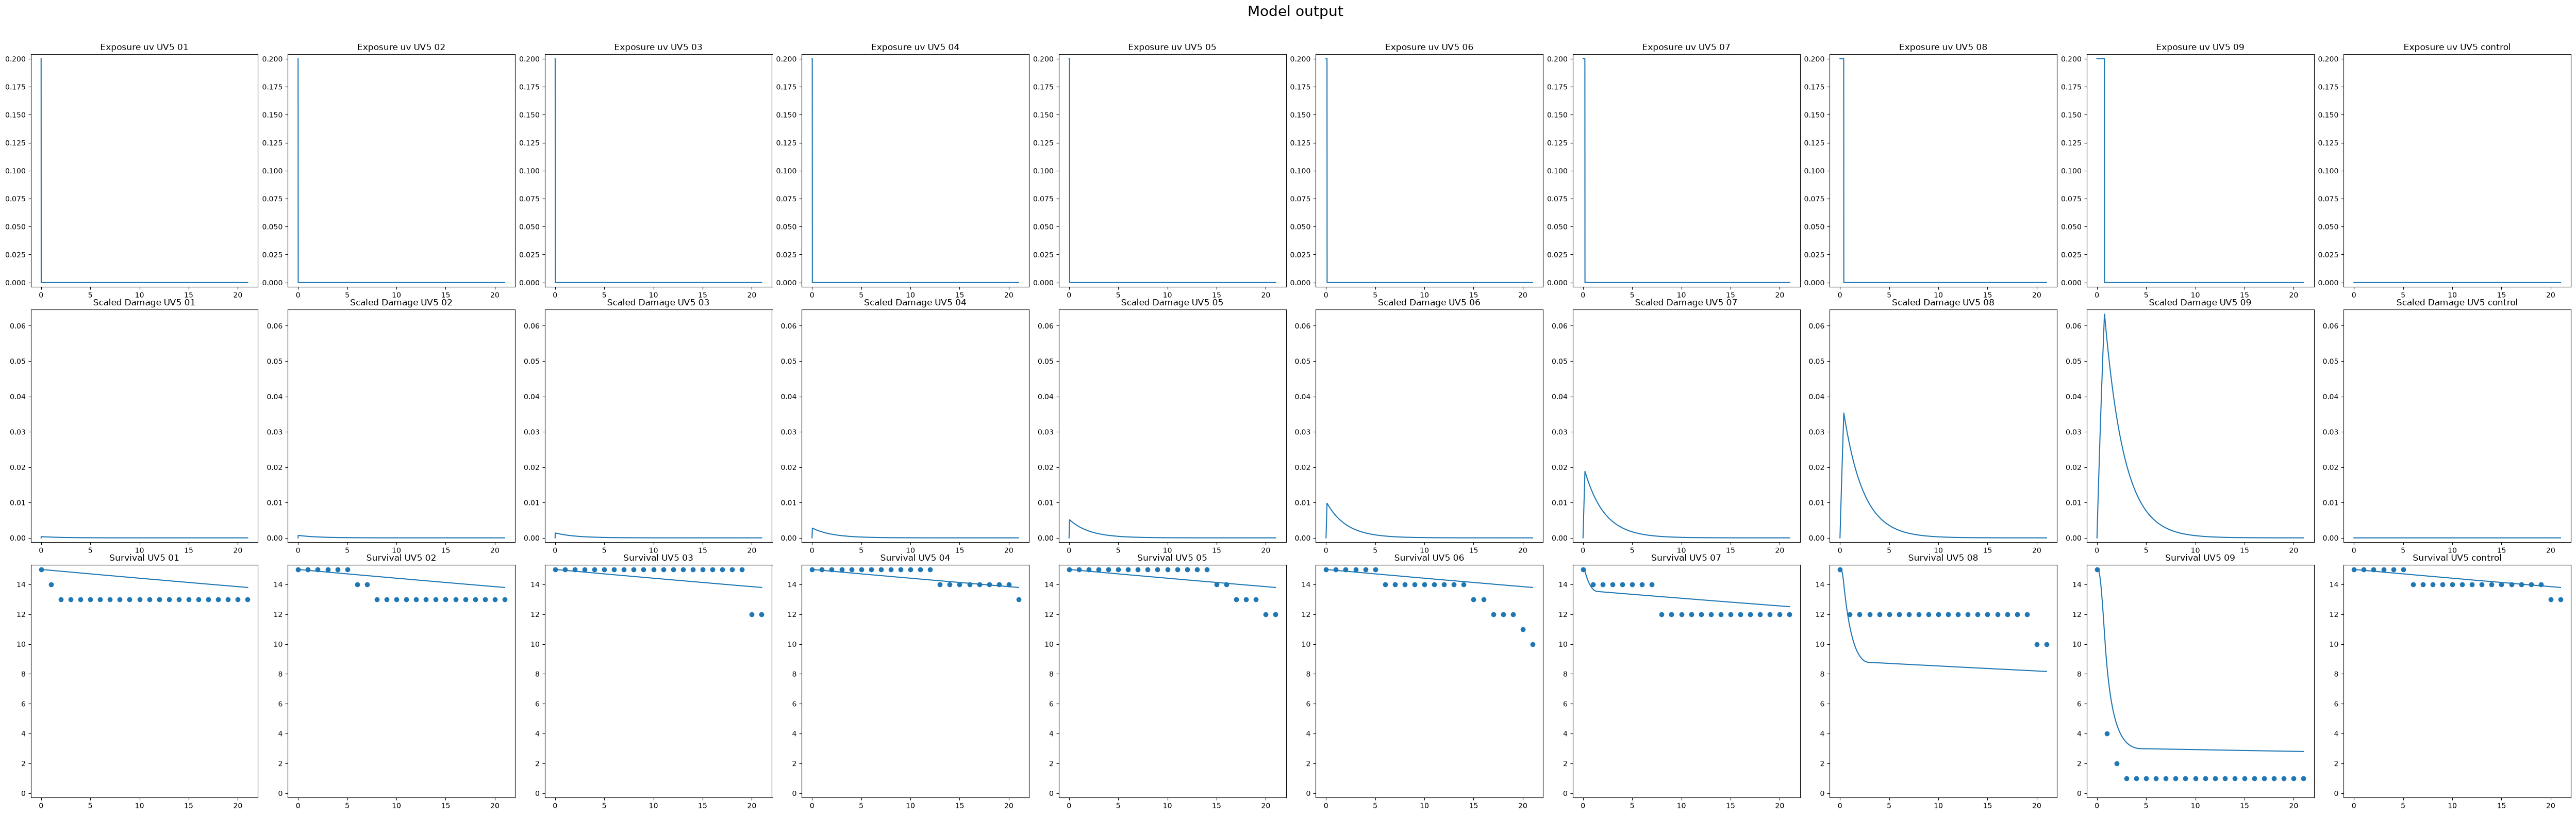

In [12]:
# Lösung

params = {
    "hb": 0.004, 
    "kd": 0.5, 
    "m":  0.01, 
    "b":  18, 
}


modelsd.plot(
    params=params,
    exposure_funcs=exposure_funcs,
    observed_data=survival_data
)

### A2c
Benutzen sie den Nelder-Mead Algorithmus von mempyguts um das SD Modell an die Daten anzupassen.

Nehmen Sie Stellung zur Modellgüte. Spiegelt das GUTS-RED-SD-Modell mit den durch den Nelder-Mead-Algorithmus inferierten Parameterwerten das beobachtete Survival angemessen wieder? Ab welcher Expositionsdauer (welchem Szenario) sagt das Modell einen signifikanten Einfluss des Stressors auf das Überleben vorher? Begründen Sie.

Model: RED_SD
Number of exposures: 1

 BEST-FIT PARAMETER VALUES
┏━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃      kd ┃      b ┃         m ┃         hb ┃
┣━━━━━━━━━╋━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━━┫
┃ 1.24318 ┃ 23.354 ┃ 0.0341495 ┃ 0.00937987 ┃
┗━━━━━━━━━┻━━━━━━━━┻━━━━━━━━━━━┻━━━━━━━━━━━━┛
Uncertainties were not calculated.

 FIT-ALGORITHM  INFO
Method: Nelder-Mead-Simplex
The background mortality was not priorly fitted to control-data.
┏━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ success   ┃   n_f_ev ┃   n_vary ┃
┣━━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━┫
┃ True      ┃      307 ┃        4 ┃
┗━━━━━━━━━━━┻━━━━━━━━━━┻━━━━━━━━━━┛
Value of the target function: [160.0192797]

 Parameter ranges
┏━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃         ┃       kd ┃        b ┃        m ┃       hb ┃
┣━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━┫
┃ min     ┃    0.001 ┃    0.001 ┃    0.001 ┃    1e-08 ┃
┣━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━┫
┃ max     ┃ 1000     ┃ 1000     

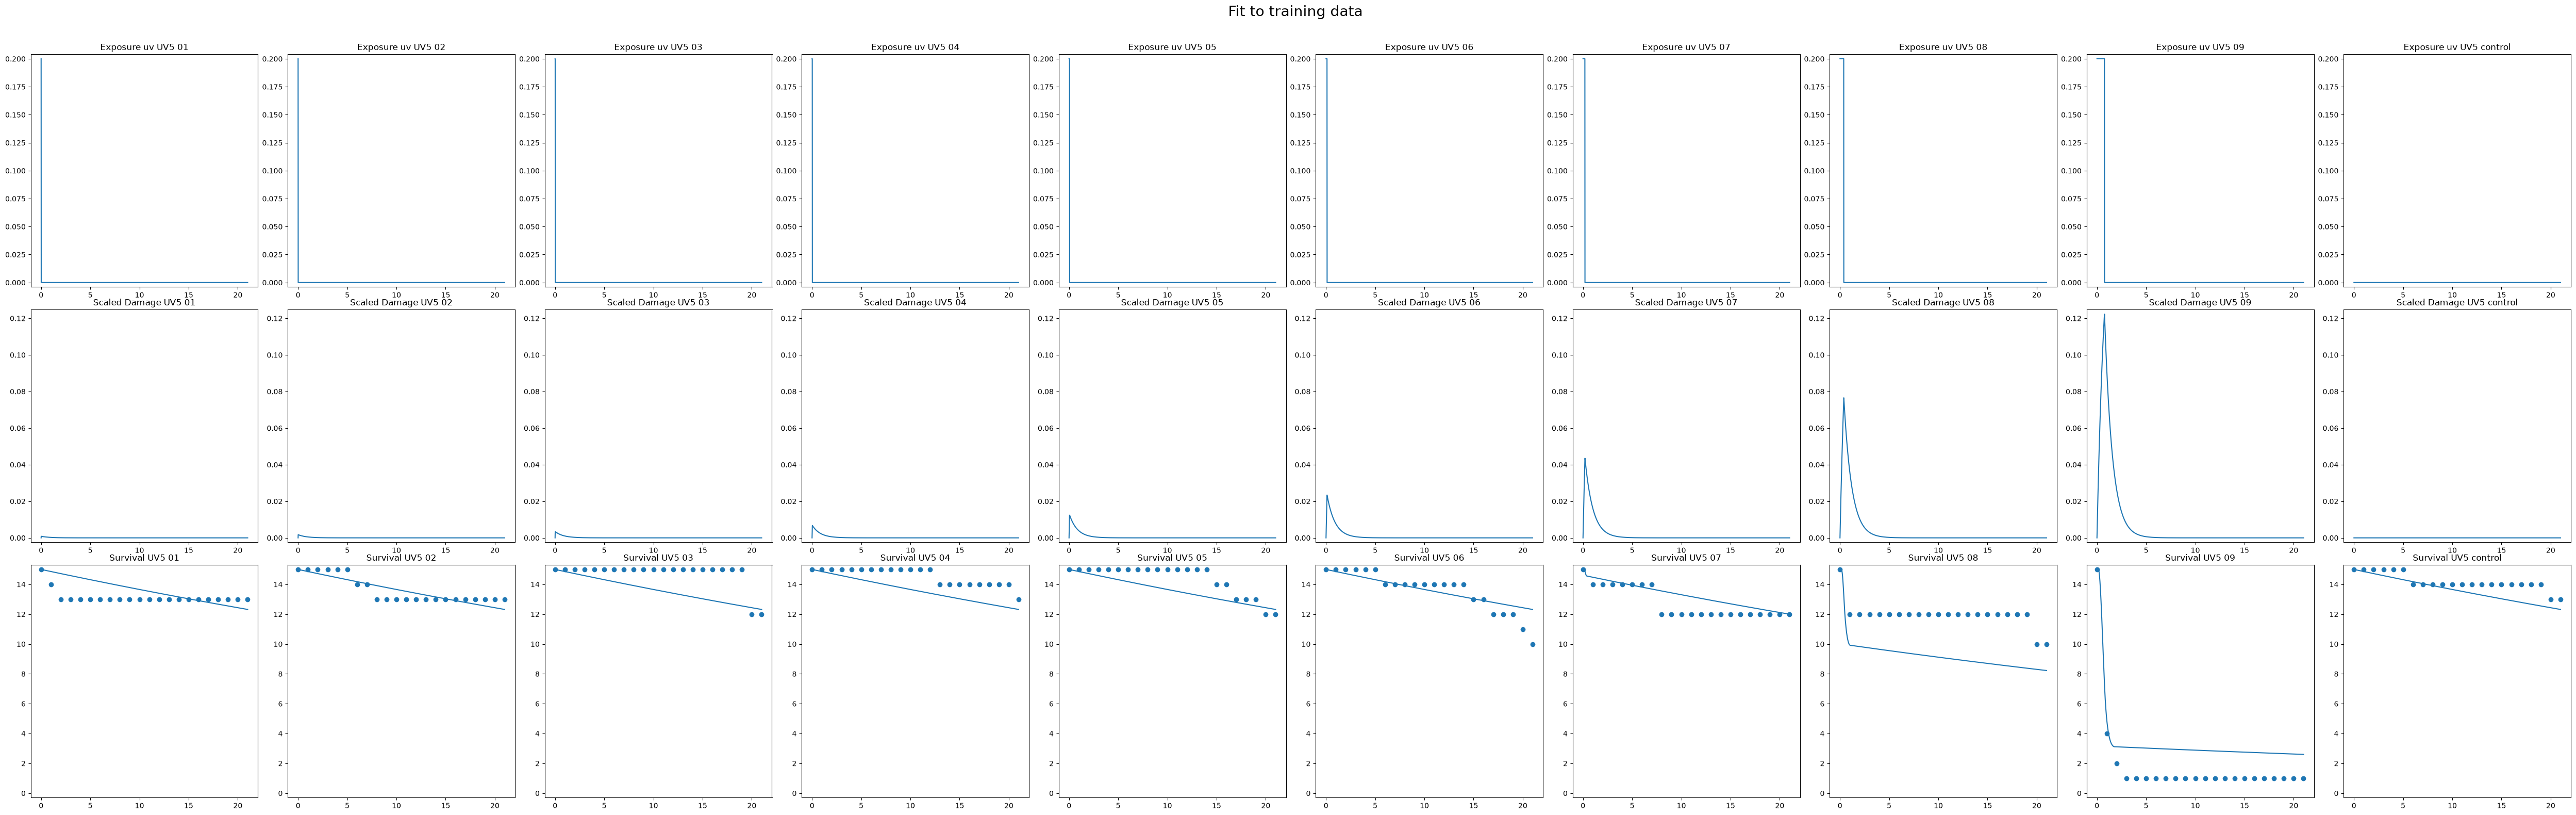

0.1048606019384683


In [24]:
#Lösung
import mempy.fit

fit_sd = mempy.fit.Fit()
#could use our params as startpoint, prob would be better

fit_sd.nelder_mead_simplex(
    model=modelsd,
    exposure_funcs=exposure_funcs,
    survival_data=survival_data,
    printres=True,
    visualize=True
)
print(fit_sd.goodness["nrmse"])

Antwort:
Der NRSME ist 0.1048606019384683. Bedeutet eine Fehler von ca. 10,5%. Das ist im allgemeinen ein guter Wert, aber ist nicht aussagekräftig für alle anpassungen. Dafür müssen alle Szenarien betrachtet werden. 
Bei 08 wir die Mortalität überschätzt, bei 09 unterstätzt. Außerdem wird bei 1-7 die Mortalität recht gut geschätzt, aber die Zeitpunkte werden nicht korrekt vorhergesagt.

Außerdem ist die Vorhersage sehr abhängig von der expositionsdauer. Je größer die Expositionsdauer wird, desto schlechter wird die Vorhersage des Modells. Wahrscheinlich lässt sich das darauf zurückführen, dass das Modell gut die Hintergrundmortalität vorhersagen kann, aber mehr Probleme mit der Exposition hat. Das müsste aber noch weiter statistisch untersucht werden. 

Es wird ein Effekt von Stressoren ab dem 0.39 Tag vorhergesehen. Das ist zu begründen dmait, dass ab Szenario 08 ein Efekt vorhergesagt wird und die Daten sagen, dass dieses Szenario eine 0.39 Day anwendung von UV Licht hatte.

### A2d

Berechnen Sie den LP50 für alle Expositionsprofile. Erstellen Sie eine Abbildung in der sie den LP50 über die Expositionsdauer mit $0.2 mW*cm^{-2}$ UV-Strahlung darstellen. Was beobachten Sie? Was sagt der LP50 aus?

<i>Hinweise:  
  
Setzten Sie das 'visualize' argument der LP_X Methode auf False, wenn Sie nicht mit 9 großen Plots konfrontiert werden wollen.  
  
Die interpolierten Expositionsobjekte in exposure_funcs[uv]["Szenario"] haben eine Methode get_knots(), welche die Zeitpunkte der Rohdaten zurückgibt und eine Methode get_coeffs(), welche die y-Werte der Rohdaten zurückgibt. Damit können Sie die Zeiten bestimmen, an denen die jeweiligen Expositionen enden.</i>

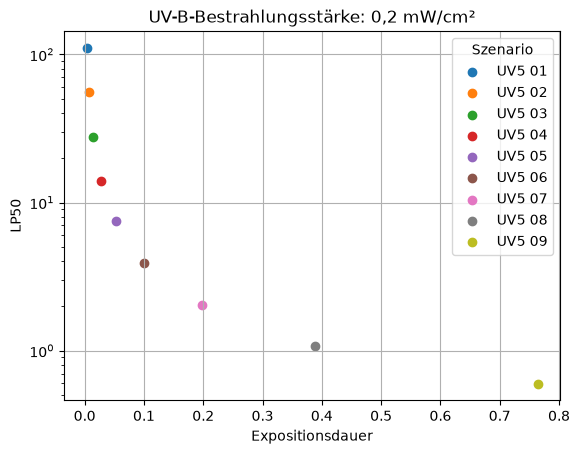

In [36]:
# Lösung
lp50_params = {}


for szenario, exposition in exposure_funcs["uv"].items():
    if "control" in szenario.lower():
        continue
    lp50_params[szenario] = modelsd.LP_X(
        params=fit_sd.params,
        exposure_funcs=exposure_funcs,
        treatment=szenario,
        X=50,
        visualize=False
    )

for szenario, lp50 in lp50_params.items():
    f = exposure_funcs["uv"][szenario]
    t = f.get_knots()
    ende = np.flatnonzero(f.get_coeffs() > 0)[-1] + 1
    plt.scatter(t[ende], lp50,label=szenario)

plt.xlabel("Expositionsdauer")
plt.ylabel("LP50")
plt.yscale("log")
plt.title("UV-B-Bestrahlungsstärke: 0,2 mW/cm²")
plt.legend(title="Szenario")
plt.grid()
plt.show()

Antwort:
Zu erkennen ist, dass je länger die Expositionsdauer ist, desto kleiner ist der LP50 Wert. Dabei ist zu erkennen, dass S08 einen LP50 Wert von ca 1 hat. Bedeutet, dass 50 Prozent des Bestands tot sind. Allgemein gibt der Lp50 Wert an mit welchem Wert die Bestrahlungstärke, multipliziert werden muss, damit 50 Prozent des Bestands sterben bis zum Ende des Betrachteten Zeitraums.

### A2e
Fitten sie auch das GUTS-RED-IT-Modell an die Daten. Schätzen Sie auch hier kurz die Modellgüte ein und beschreiben Sie Gemeinsamkeiten und Unterschiede in den Modellvorhersagen. Erklären Sie, wie die Form der Survival-Kurven zustande kommt; Warum nimmt das Survival bei längeren Expositionsdauern so plötzlich ab und nach Ende der Exposition nur langsam?

Model: RED_IT
Number of exposures: 1

 BEST-FIT PARAMETER VALUES
┏━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┓
┃      kd ┃         m ┃    beta ┃        hb ┃
┣━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━╋━━━━━━━━━━━┫
┃ 3.60882 ┃ 0.0420307 ┃ 1.60843 ┃ 0.0101165 ┃
┗━━━━━━━━━┻━━━━━━━━━━━┻━━━━━━━━━┻━━━━━━━━━━━┛
Uncertainties were not calculated.

 FIT-ALGORITHM  INFO
Method: Nelder-Mead-Simplex
The background mortality was not priorly fitted to control-data.
┏━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ success   ┃   n_f_ev ┃   n_vary ┃
┣━━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━┫
┃ True      ┃      243 ┃        4 ┃
┗━━━━━━━━━━━┻━━━━━━━━━━┻━━━━━━━━━━┛
Value of the target function: [165.64860963]

 Parameter ranges
┏━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃         ┃       kd ┃        m ┃     beta ┃       hb ┃
┣━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━┫
┃ min     ┃    0.001 ┃    0.001 ┃    0.001 ┃    1e-08 ┃
┣━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━┫
┃ max     ┃ 1000     ┃ 1000    

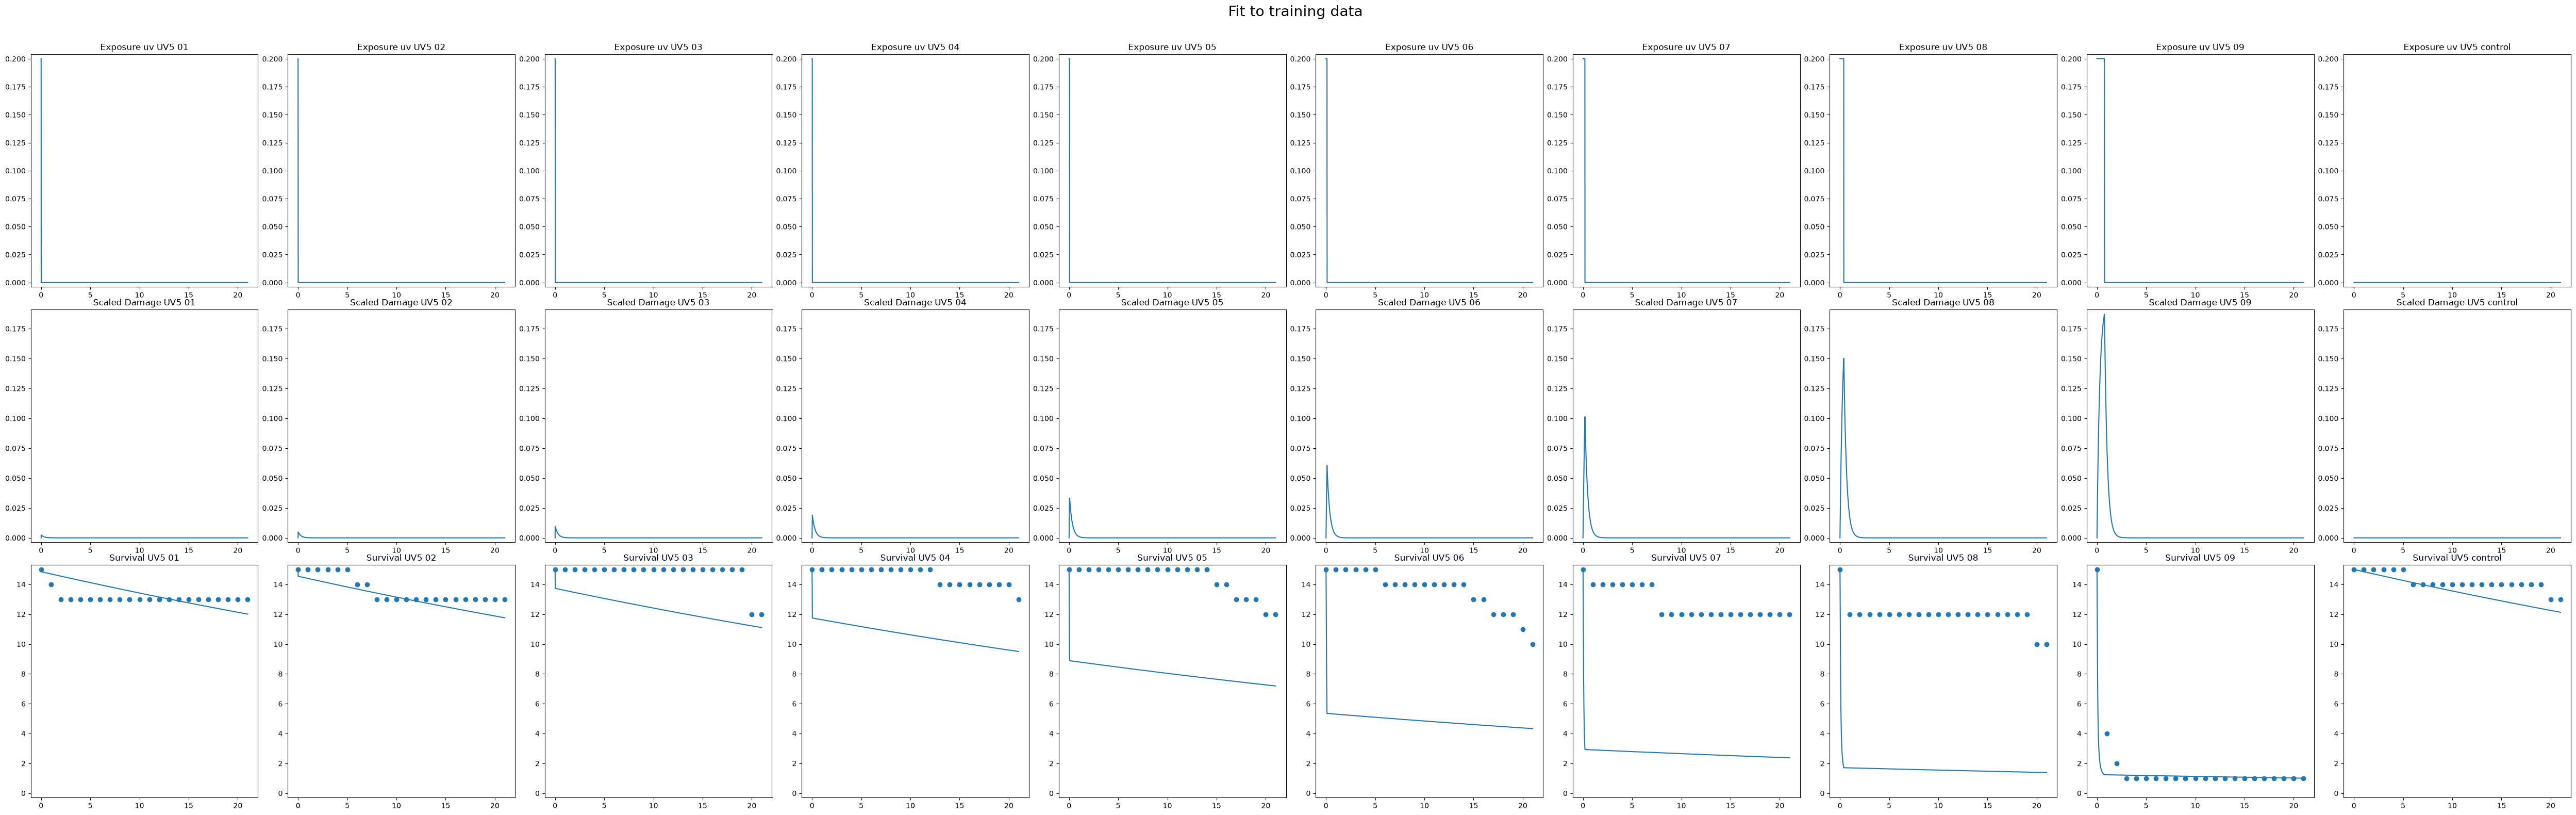

NRMSE SD: 0.1048606019384683
NRMSE IT: 0.09445797218755786


In [37]:
# Lösung
from mempy.model import RED_IT

modelit = RED_IT()
fit_it = mempy.fit.Fit()

fit_it.nelder_mead_simplex(
    model=modelit,
    exposure_funcs=exposure_funcs,
    survival_data=survival_data,
    printres=True,
    visualize=True
)

print("NRMSE SD:", fit_sd.goodness["nrmse"])
print("NRMSE IT:", fit_it.goodness["nrmse"])

Antwort:
Allgmein beschreibt der NRMSE eine bessere allgemeine Anpassung an die Daten. Trotzdem passt der IT Fit deutlich schlechter zu den Daten, da das IT Model bereits bei kürzeren Bestrahlungen einen Effekt prognostiziert. Bei dem IT Modell haben die Tiere unterschiedliche Thresholds. Deswegen sterben bereits am Anfang welche. Bei dem SD Modell kann man sehen, dass zuerst ein allgemeiner Threshold überschritten werden muss, damit Tiere beginnen zu sterben. 

## Augabe 3: GUTS-Mixtures

Gemische von Chemikalien sind ein sehr realer Bestandteil der Umwelt und sie Stellen sowohl Tiere als auch Menschen vor Herausforderungen. Die Anzahl der aktuell kommerziell gehandelten Chemikalien liegt bei 50,000. Nimmt man alle Chemikalien hinzu die in der Vergangenheit gehandelt werden sind wir bei 350,000 Substanzen. Diese Menge kann auf Organismen in unterschiedlichen Konzentrationen wirken. Bisher haben wir uns nur mit der Wirkung einer Substanz (bzw. eines Stressors UV-B Strahlung beschäftigt). Zu den Chemikalen kommen nämlich noch natürliche Stressoren hinzu.  
  
Die folgenden Daten sind das Ergebnis von Versuchen mit den beiden Stressoren in Isolation. Die Treatments "UV5 01" - "UV5 09" sind die selben, die in Aufgaben 2 verwendet wurden, also nur Exposition zu UV-B Strahlung. Die Treatments "UVP5 01" - "UVP2 01" beinhaltet eine reine Exposition mit Esfenvalerate ohne UV-B-Strahlung.

In [16]:
exposure_funcs_calibration_mix, survival_data_calibration_mix, num_expos_calibration_mix = mempy.input_data.read_exposure_survival(
    "data/uvb_esfenvalerate/mix/", "openguts_survival.xlsx", 
    exposure_name="exposure_",
    survival_name="survival",
    info_name="meta",
    visualize=False
)

### A3a
Warum kalibriert man die Modelle an Experimente mit den isolierten Stressoren und nicht an die Mischung?

Antwort:

### A3b
Kalibrieren Sie das GUTS-RED-SD-DA (Damage Addition) Modell an die gegebenen Daten mit Hilfe des Nelder-Mead-Simplex Algorithmus aus mempy. Schätzen Sie zunächst kurz den Fit des Modells an seine Trainingsdaten ein. Beschreiben Sie Unterschiede der Vorhersage für die Zeitreihen mit reiner Exposition mit UV-B-Strahlung zu Aufgabe 2.

In [17]:
# Lösung

Antwort:

Um zu sehen ob das Modell nun tatsächlich auch die Mischungstoxizität vorhersagen kann müssen wir die kalibrierten Parameterwerte mit tatsächlicher Exposition an die Mischung der Stressoren simulieren und nicht wie bisher nur die isolierten Stressoren. Dafür gibt es einen Validierungsdatensatz in dem die Stressoren gemeinsam getestet wurden.

### A3c

Simulieren Sie das GUTS-RED-SD-DA Modell mit den kalibrierten Parametern unter der hier importierten gleichzeitigen Exposition mit Esfenvalerate und UV-B-Strahlung. Plotten Sie die Modellvorhersage und die beobachteten Überlebensdaten zusammen und berechnen Sie den NRMSE. Schätzen Sie kurz die Vorhersagekraft des Modells für die Validierungsdaten ein. Beschreiben Sie die Überschätzung der Mortalität in den Treatments "UVP5 07" bis "UVP9 11" und erklären Sie wie diese zustandekommt. Argumentieren Sie unter Einbeziehung der Kalibrierungsergebnisse und überlegen Sie wie man diese Überschätzung biologisch/chemisch erklären könnte.

In [18]:
exposure_funcs_validation_mix, survival_data_validation_mix, num_expos_validation_mix = mempy.input_data.read_exposure_survival(
    "data/uvb_esfenvalerate/2020_03_UVP_pulse_5/", "openguts_survival.xlsx", 
    exposure_name="exposure_",
    survival_name="survival",
    info_name="meta",
    visualize= False
)

In [19]:
# Lösung

Antwort: